# Eksperimen Kompresi Dinamika: Rasio 2:1 vs 3:1 vs 4:1

Notebook ini membandingkan efek **rasio kompresi** pada rekaman `audio/dynamic.m4a` yang punya perbedaan keras–lirih yang jelas.

**Alur eksperimen:**
1. Memuat audio dan melihat **dinamika aslinya** (waveform + amplop RMS dBFS).
2. Menentukan **threshold** kompresor dari distribusi level rekaman itu sendiri, bukan dari angka asal.
3. Menerapkan `pedalboard.Compressor` dengan rasio **2:1, 3:1, 4:1** (threshold, attack, release sama).
4. Menyamakan kenyaringan semua versi ke **−16 LUFS** supaya perbandingan dengar adil.
5. Membandingkan waveform, amplop RMS, *gain reduction*, metrik dinamika, dan **playback**.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import librosa
import soundfile as sf
import pyloudnorm as pyln
from pedalboard import Pedalboard, Compressor, Limiter, NoiseGate, Gain, HighpassFilter
import IPython.display as ipd
from IPython.display import display
import pydub

# Konfigurasi visualisasi
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

# Palet warna resmi modul
C_SIGNAL   = '#0284c7'   # biru   — sinyal utama
C_ALT      = '#0ea5e9'   # langit — sinyal sekunder
C_NEUTRAL  = '#334155'   # slate  — teks / waveform mentah
C_ALERT    = '#dc2626'   # merah  — clipping / gain reduction
C_GOOD     = '#059669'   # hijau  — aman / gated
C_ACCENT   = '#7c3aed'   # violet — kompresi
C_GOLD     = '#c5a059'   # emas   — limiter / target

In [2]:
# Fungsi bantu yang dipakai di seluruh notebook
HOP_MS   = 10      # resolusi amplop RMS (10 ms per titik)
FRAME_MS = 50      # panjang jendela RMS

def amplop_db(x, sr):
    # Amplop RMS dalam dBFS dengan resolusi 10 ms
    hop = int(sr * HOP_MS / 1000)
    frame = int(sr * FRAME_MS / 1000)
    rms = librosa.feature.rms(y=x, frame_length=frame, hop_length=hop)[0]
    t = librosa.frames_to_time(np.arange(len(rms)), sr=sr, hop_length=hop)
    return t, 20 * np.log10(np.maximum(rms, 1e-6))

def peak_db(x):
    return 20 * np.log10(np.max(np.abs(x)) + 1e-12)

def rms_db(x):
    return 20 * np.log10(np.sqrt(np.mean(x ** 2)) + 1e-12)

def putar(x, sr, label):
    # normalize=False agar browser tidak menyamakan volume — perbedaan level tetap terdengar apa adanya
    print(label)
    display(ipd.Audio(x, rate=sr, normalize=False))

## 1. Memuat Audio

Berkas `.m4a` (AAC) tidak bisa dibaca langsung oleh `soundfile`/`librosa`, jadi kita konversi dulu ke `.wav` dengan `pydub` (butuh `ffmpeg`). Konversi hanya dilakukan sekali; jika `dynamic.wav` sudah ada, berkas itu langsung dipakai.

In [3]:
from pydub import AudioSegment

# Cari folder audio, baik notebook dijalankan dari notebook_handson/ maupun dari root repo
AUDIO_DIR = next(p for p in ["audio", "notebook_handson/audio", "../audio"] if os.path.isdir(p))
audio_path_m4a = os.path.join(AUDIO_DIR, "dynamic.m4a")
audio_path     = os.path.join(AUDIO_DIR, "dynamic.wav")

# Konversi m4a -> wav (requires ffmpeg installed)
if not os.path.exists(audio_path):
    AudioSegment.from_file(audio_path_m4a, format="m4a").export(audio_path, format="wav")

y, sr = librosa.load(audio_path, sr=None, mono=True)
t = np.arange(len(y)) / sr

print(f"Loaded      : {audio_path}")
print(f"Sample rate : {sr} Hz")
print(f"Duration    : {len(y)/sr:.2f} s")

putar(y, sr, "\n🔊 Audio asli:")

Loaded      : audio/dynamic.wav
Sample rate : 48000 Hz
Duration    : 16.40 s

🔊 Audio asli:


## 2. Preview Dinamika Audio Asli

Waveform saja kurang jelas untuk membaca dinamika, karena amplitudo linear "memampatkan" bagian lirih. Karena itu kita tampilkan juga **amplop RMS dalam dBFS** (skala logaritmik, mirip cara telinga menilai kenyaringan).

Metrik yang dihitung:
- **Peak** dan **RMS** keseluruhan (dBFS).
- **Crest factor** = Peak − RMS → seberapa "runcing" puncak dibanding energi rata-rata.
- **Integrated loudness** (LUFS, ITU-R BS.1770).
- **Rentang dinamika (DR)** = persentil-95 − persentil-10 amplop RMS pada frame **aktif** (frame hening/derau dibuang supaya tidak menggelembungkan angka).
- **Sampel ter-*clip***: jumlah sampel yang menyentuh 0 dBFS.

Peak            :   0.00 dBFS
RMS             : -11.46 dBFS
Crest factor    :  11.46 dB
Loudness        : -10.10 LUFS
Noise floor     : -34.13 dBFS
Rentang dinamika:  19.00 dB  (P95 − P10 frame aktif)
Sampel ter-clip : 22028 sampel (2.80%)


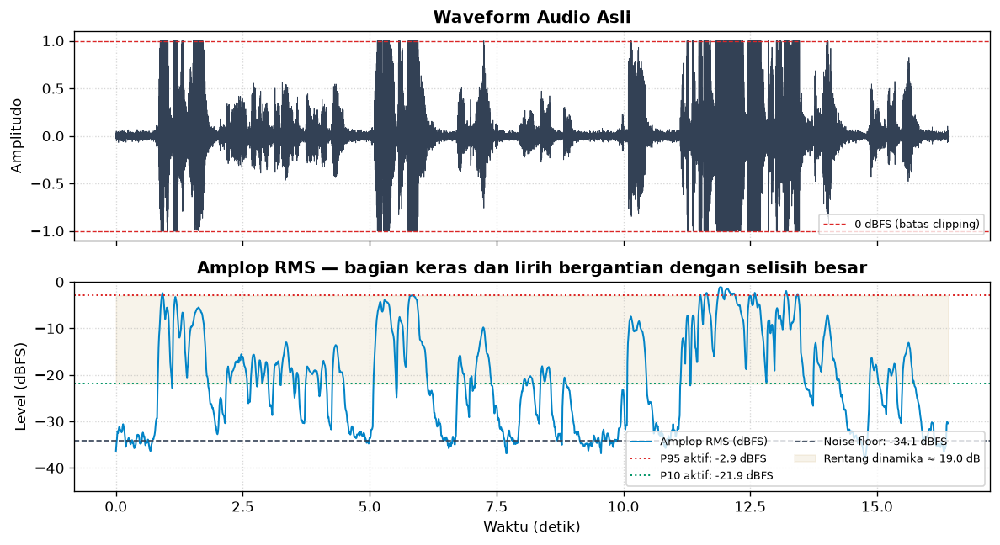

In [4]:
t_env, env_db = amplop_db(y, sr)

# Frame aktif = 10 dB di atas derau latar (persentil-10 seluruh frame)
noise_floor = np.percentile(env_db, 10)
aktif = env_db > noise_floor + 10

def rentang_dinamika(x):
    # DR = P95 - P10 amplop RMS pada frame aktif (mask aktif diambil dari audio asli)
    _, e = amplop_db(x, sr)
    return np.percentile(e[aktif], 95) - np.percentile(e[aktif], 10)

meter = pyln.Meter(sr)
lufs_asli = meter.integrated_loudness(y)
n_clip = np.sum(np.abs(y) >= 0.999)

print(f"Peak            : {peak_db(y):6.2f} dBFS")
print(f"RMS             : {rms_db(y):6.2f} dBFS")
print(f"Crest factor    : {peak_db(y) - rms_db(y):6.2f} dB")
print(f"Loudness        : {lufs_asli:6.2f} LUFS")
print(f"Noise floor     : {noise_floor:6.2f} dBFS")
print(f"Rentang dinamika: {rentang_dinamika(y):6.2f} dB  (P95 − P10 frame aktif)")
print(f"Sampel ter-clip : {n_clip} sampel ({100 * n_clip / len(y):.2f}%)")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)

ax1.plot(t, y, color=C_NEUTRAL, lw=0.5)
ax1.axhline(1.0, color=C_ALERT, ls='--', lw=0.8)
ax1.axhline(-1.0, color=C_ALERT, ls='--', lw=0.8, label='0 dBFS (batas clipping)')
ax1.set_ylim(-1.1, 1.1)
ax1.set_ylabel("Amplitudo")
ax1.set_title("Waveform Audio Asli", fontweight='bold')
ax1.legend(loc='lower right', fontsize=8)
ax1.grid(True, ls=':', alpha=0.5)

p95, p10 = np.percentile(env_db[aktif], 95), np.percentile(env_db[aktif], 10)
ax2.plot(t_env, env_db, color=C_SIGNAL, lw=1.2, label='Amplop RMS (dBFS)')
ax2.axhline(p95, color=C_ALERT, ls=':', lw=1.2, label=f'P95 aktif: {p95:.1f} dBFS')
ax2.axhline(p10, color=C_GOOD, ls=':', lw=1.2, label=f'P10 aktif: {p10:.1f} dBFS')
ax2.axhline(noise_floor, color=C_NEUTRAL, ls='--', lw=1, label=f'Noise floor: {noise_floor:.1f} dBFS')
ax2.fill_between(t_env, p10, p95, color=C_GOLD, alpha=0.12, label=f'Rentang dinamika ≈ {p95 - p10:.1f} dB')
ax2.set_ylim(-45, 0)
ax2.set_xlabel("Waktu (detik)")
ax2.set_ylabel("Level (dBFS)")
ax2.set_title("Amplop RMS — bagian keras dan lirih bergantian dengan selisih besar", fontweight='bold')
ax2.legend(loc='lower right', fontsize=7.5, ncol=2)
ax2.grid(True, ls=':', alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Menentukan Threshold yang Ideal

Threshold yang baik **tidak ditebak**, tapi dibaca dari distribusi level rekaman:
- Jika threshold **terlalu rendah** (mis. −30 dBFS), bagian lirih pun ikut ditekan → seluruh rekaman "dipencet", terdengar datar dan *pumping*, dan derau ikut terangkat setelah *makeup gain*.
- Jika threshold **terlalu tinggi** (mis. −6 dBFS), hanya puncak sesaat yang tersentuh → perbedaan keras–lirih nyaris tidak berubah.

Tujuan kita: **bagian lirih dibiarkan utuh, hanya bagian keras yang diredam**. Jadi threshold diletakkan di **celah antara kelompok level lirih dan kelompok level keras**. Histogram level frame aktif di bawah memperlihatkan dua kelompok itu; titik tengah yang praktis adalah **median level frame aktif**, dibulatkan ke dB terdekat.

Median level frame aktif : -15.33 dBFS
→ THRESHOLD dipilih      :  -15.0 dBFS
Level tipikal bagian lirih: -19.35 dBFS (4.9 s)
Level tipikal bagian keras:  -7.78 dBFS (4.8 s)


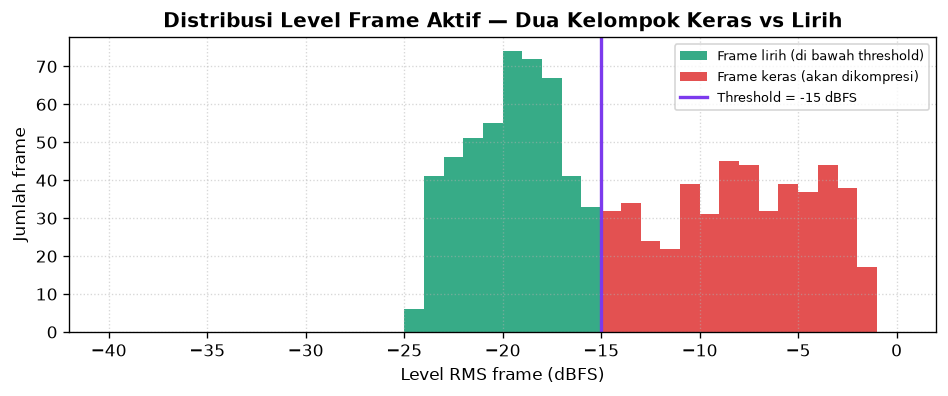

In [5]:
lvl_aktif = env_db[aktif]
THRESHOLD_DB = float(np.round(np.median(lvl_aktif)))

lirih = aktif & (env_db < THRESHOLD_DB)
keras = aktif & (env_db >= THRESHOLD_DB)

print(f"Median level frame aktif : {np.median(lvl_aktif):6.2f} dBFS")
print(f"→ THRESHOLD dipilih      : {THRESHOLD_DB:6.1f} dBFS")
print(f"Level tipikal bagian lirih: {np.median(env_db[lirih]):6.2f} dBFS ({lirih.sum() * HOP_MS / 1000:.1f} s)")
print(f"Level tipikal bagian keras: {np.median(env_db[keras]):6.2f} dBFS ({keras.sum() * HOP_MS / 1000:.1f} s)")

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(-40, 1, 1)
ax.hist(env_db[lirih], bins=bins, color=C_GOOD, alpha=0.8, label='Frame lirih (di bawah threshold)')
ax.hist(env_db[keras], bins=bins, color=C_ALERT, alpha=0.8, label='Frame keras (akan dikompresi)')
ax.axvline(THRESHOLD_DB, color=C_ACCENT, lw=2, label=f'Threshold = {THRESHOLD_DB:.0f} dBFS')
ax.set_xlabel("Level RMS frame (dBFS)")
ax.set_ylabel("Jumlah frame")
ax.set_title("Distribusi Level Frame Aktif — Dua Kelompok Keras vs Lirih", fontweight='bold')
ax.legend(fontsize=8)
ax.grid(True, ls=':', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Parameter Kompresor & Kurva Transfer

Semua parameter selain rasio **dibuat sama** agar perbedaan hasil murni berasal dari rasio:

| Parameter | Nilai | Alasan |
|---|---|---|
| Threshold | hasil §3 | di antara kelompok lirih dan keras |
| Attack | 5 ms | cukup cepat menangkap awal bagian keras, tetapi tidak memotong habis transien sehingga suara tetap natural |
| Release | 120 ms | cukup lambat agar tidak "bergetar" mengikuti tiap siklus gelombang, cukup cepat agar bagian lirih setelahnya tidak ikut teredam |
| Rasio | 2:1, 3:1, 4:1 | kompresi ringan → sedang → kuat |

Kurva transfer statis: di atas threshold $T$, setiap kenaikan input $\Delta$ dB hanya menghasilkan kenaikan output $\Delta / R$ dB:

$$y_{\text{dB}} = \begin{cases} x_{\text{dB}} & x_{\text{dB}} \le T \\ T + \dfrac{x_{\text{dB}} - T}{R} & x_{\text{dB}} > T \end{cases}$$

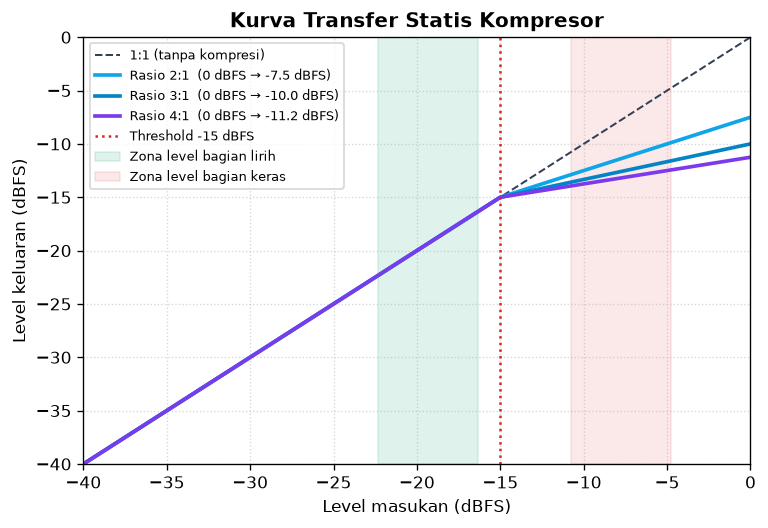

In [6]:
ATTACK_MS  = 5.0
RELEASE_MS = 120.0
RASIO      = [2.0, 3.0, 4.0]
WARNA      = {'Asli': C_NEUTRAL, '2:1': C_ALT, '3:1': C_SIGNAL, '4:1': C_ACCENT}

x_db = np.linspace(-40, 0, 400)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(x_db, x_db, color=C_NEUTRAL, ls='--', lw=1.2, label='1:1 (tanpa kompresi)')
for R in RASIO:
    y_db = np.where(x_db <= THRESHOLD_DB, x_db, THRESHOLD_DB + (x_db - THRESHOLD_DB) / R)
    ax.plot(x_db, y_db, color=WARNA[f'{R:.0f}:1'], lw=2.2, label=f'Rasio {R:.0f}:1  (0 dBFS → {y_db[-1]:.1f} dBFS)')
ax.axvline(THRESHOLD_DB, color=C_ALERT, ls=':', lw=1.5, label=f'Threshold {THRESHOLD_DB:.0f} dBFS')
ax.axvspan(np.median(env_db[lirih]) - 3, np.median(env_db[lirih]) + 3, color=C_GOOD, alpha=0.12, label='Zona level bagian lirih')
ax.axvspan(np.median(env_db[keras]) - 3, np.median(env_db[keras]) + 3, color=C_ALERT, alpha=0.10, label='Zona level bagian keras')
ax.set_xlim(-40, 0)
ax.set_ylim(-40, 0)
ax.set_xlabel("Level masukan (dBFS)")
ax.set_ylabel("Level keluaran (dBFS)")
ax.set_title("Kurva Transfer Statis Kompresor", fontweight='bold')
ax.legend(fontsize=7.5, loc='upper left')
ax.grid(True, ls=':', alpha=0.5)
plt.tight_layout()
plt.show()

### Menerapkan Kompresi + Penyamaan Loudness

Kompresi menurunkan level bagian keras, sehingga hasilnya **lebih pelan** daripada aslinya. Kalau langsung dibandingkan, telinga cenderung menganggap versi yang lebih keras "lebih bagus" (*loudness bias*). Karena itu setiap versi — termasuk audio asli — diberi *makeup gain* hingga **−16 LUFS** (standar podcast/Apple). Dengan kenyaringan rata-rata yang sama, perbedaan yang terdengar murni berasal dari **dinamika**.

Sinyal sebelum *makeup gain* tetap disimpan (`mentah`) untuk menghitung *gain reduction* yang sebenarnya dilakukan kompresor.

In [7]:
TARGET_LUFS = -16.0

def samakan_loudness(x):
    return pyln.normalize.loudness(x, meter.integrated_loudness(x), TARGET_LUFS)

mentah = {'Asli': y}
for R in RASIO:
    comp = Compressor(threshold_db=THRESHOLD_DB, ratio=R, attack_ms=ATTACK_MS, release_ms=RELEASE_MS)
    mentah[f'{R:.0f}:1'] = comp(y.astype(np.float32), sr)

versi = {k: samakan_loudness(v) for k, v in mentah.items()}

for k in versi:
    makeup = TARGET_LUFS - meter.integrated_loudness(mentah[k])
    print(f"[{k:>4s}] loudness sebelum makeup: {meter.integrated_loudness(mentah[k]):6.2f} LUFS | "
          f"makeup gain: {makeup:+6.2f} dB | peak akhir: {peak_db(versi[k]):6.2f} dBFS")

[Asli] loudness sebelum makeup: -10.10 LUFS | makeup gain:  -5.90 dB | peak akhir:  -5.90 dBFS
[ 2:1] loudness sebelum makeup: -16.95 LUFS | makeup gain:  +0.95 dB | peak akhir:  -1.69 dBFS
[ 3:1] loudness sebelum makeup: -18.74 LUFS | makeup gain:  +2.74 dB | peak akhir:  -0.78 dBFS
[ 4:1] loudness sebelum makeup: -19.61 LUFS | makeup gain:  +3.61 dB | peak akhir:  -0.35 dBFS


## 5. Perbandingan Waveform

Keempat waveform di bawah sudah disamakan loudness-nya dan memakai **skala sumbu-y yang sama**. Perhatikan: semakin besar rasio, bagian keras makin "dipangkas" mendekati tinggi bagian lirih — bentuk waveform makin **rata seperti balok**.

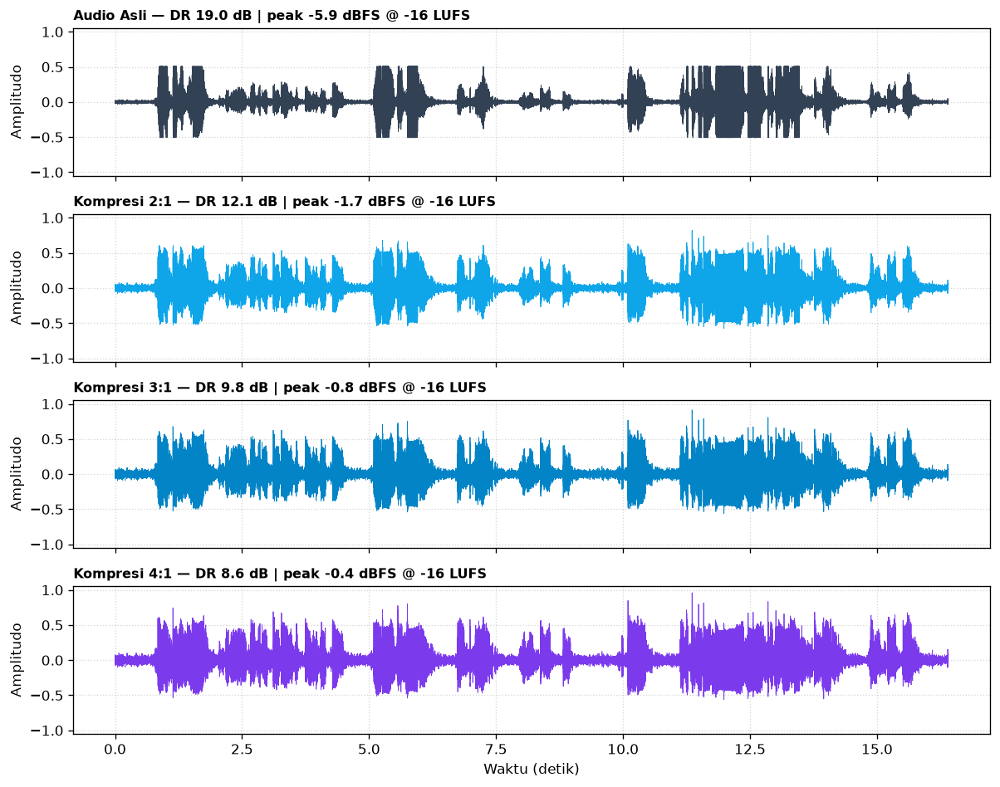

In [8]:
fig, axes = plt.subplots(len(versi), 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, (k, x) in zip(axes, versi.items()):
    ax.plot(t, x, color=WARNA[k], lw=0.5)
    judul = "Audio Asli" if k == 'Asli' else f"Kompresi {k}"
    ax.set_title(f"{judul} — DR {rentang_dinamika(x):.1f} dB | peak {peak_db(x):.1f} dBFS @ {TARGET_LUFS:.0f} LUFS",
                 fontweight='bold', fontsize=9.5, loc='left')
    ax.set_ylabel("Amplitudo")
    ax.set_ylim(-1.05, 1.05)
    ax.grid(True, ls=':', alpha=0.5)

axes[-1].set_xlabel("Waktu (detik)")
plt.tight_layout()
plt.show()

### Amplop RMS & Gain Reduction

Panel atas menumpuk amplop RMS keempat versi (setelah penyamaan loudness): bagian keras turun, bagian lirih naik, sehingga jaraknya menyempit.

Panel bawah menunjukkan **gain reduction** — berapa dB kompresor menurunkan sinyal di tiap waktu (dihitung dari sinyal sebelum *makeup gain*). Idealnya, gain reduction ≈ 0 dB di bagian lirih dan hanya aktif di bagian keras.

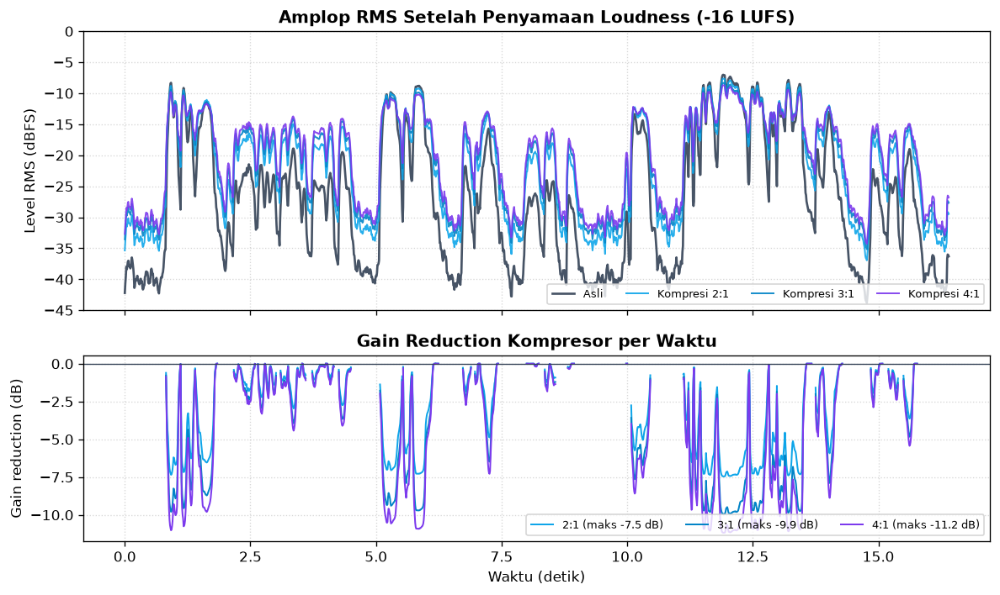

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

for k, x in versi.items():
    te, e = amplop_db(x, sr)
    ax1.plot(te, e, color=WARNA[k], lw=1.6 if k == 'Asli' else 1.2,
             alpha=0.9, label=k if k == 'Asli' else f'Kompresi {k}')
ax1.set_ylim(-45, 0)
ax1.set_ylabel("Level RMS (dBFS)")
ax1.set_title(f"Amplop RMS Setelah Penyamaan Loudness ({TARGET_LUFS:.0f} LUFS)", fontweight='bold')
ax1.legend(loc='lower right', fontsize=8, ncol=4)
ax1.grid(True, ls=':', alpha=0.5)

for k in RASIO:
    k = f'{k:.0f}:1'
    _, e_comp = amplop_db(mentah[k], sr)
    gr = np.where(aktif, e_comp - env_db, np.nan)   # sembunyikan frame hening
    ax2.plot(t_env, gr, color=WARNA[k], lw=1.2, label=f'{k} (maks {np.nanmin(gr):.1f} dB)')
ax2.axhline(0, color=C_NEUTRAL, lw=0.8)
ax2.set_ylabel("Gain reduction (dB)")
ax2.set_xlabel("Waktu (detik)")
ax2.set_title("Gain Reduction Kompresor per Waktu", fontweight='bold')
ax2.legend(loc='lower right', fontsize=8, ncol=3)
ax2.grid(True, ls=':', alpha=0.5)

plt.tight_layout()
plt.show()

### Zoom: Transisi Lirih → Keras

Memperbesar area di sekitar detik ke-4 s.d. 7, saat rekaman berpindah dari bagian lirih ke bagian keras. Di sini terlihat jelas bagaimana kompresor **menahan lonjakan** level saat bagian keras dimulai.

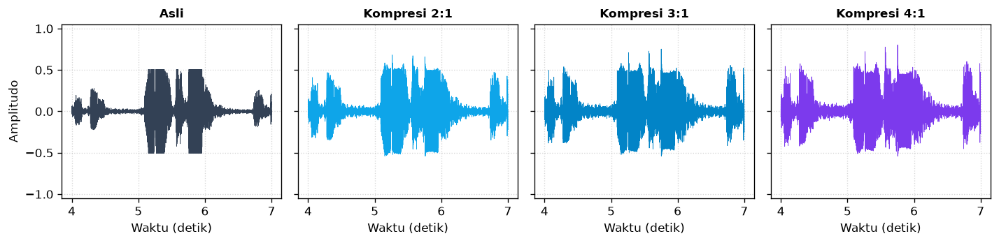

In [10]:
ZOOM = (4.0, 7.0)   # detik
i0, i1 = int(ZOOM[0] * sr), int(ZOOM[1] * sr)

fig, axes = plt.subplots(1, len(versi), figsize=(12, 3), sharey=True)
for ax, (k, x) in zip(axes, versi.items()):
    ax.plot(t[i0:i1], x[i0:i1], color=WARNA[k], lw=0.5)
    ax.set_title("Asli" if k == 'Asli' else f"Kompresi {k}", fontweight='bold', fontsize=10)
    ax.set_xlabel("Waktu (detik)")
    ax.set_ylim(-1.05, 1.05)
    ax.grid(True, ls=':', alpha=0.5)
axes[0].set_ylabel("Amplitudo")
plt.tight_layout()
plt.show()

## 6. Metrik Dinamika

- **Selisih keras–lirih**: median level frame keras − median level frame lirih (frame dikelompokkan berdasarkan audio asli). Ini angka paling intuitif untuk "perbedaan dinamis".
- **DR (P95−P10)**: rentang dinamika keseluruhan frame aktif.
- **Gain reduction bagian lirih**: idealnya mendekati 0 dB — bukti threshold tidak terlalu rendah.
- **Crest factor**: Peak − RMS sampel. Kompresor dengan attack 5 ms meloloskan sebagian transien awal, sehingga crest factor **tidak** otomatis turun. Untuk memangkas puncak sesaat, alat yang tepat adalah *limiter*, bukan kompresor.

Threshold -15 dBFS | attack 5 ms | release 120 ms | semua versi @ -16 LUFS

Versi   Selisih keras-lirih       DR   GR lirih   GR keras    Crest      Peak
-----------------------------------------------------------------------------
Asli                11.6 dB  19.0 dB     0.0 dB     0.0 dB  11.5 dB  -5.9 dBFS
2:1                  6.5 dB  12.1 dB    -0.7 dB    -5.9 dB  14.7 dB  -1.7 dBFS
3:1                  4.9 dB   9.8 dB    -0.9 dB    -7.9 dB  15.4 dB  -0.8 dBFS
4:1                  4.2 dB   8.6 dB    -1.0 dB    -8.8 dB  15.8 dB  -0.4 dBFS


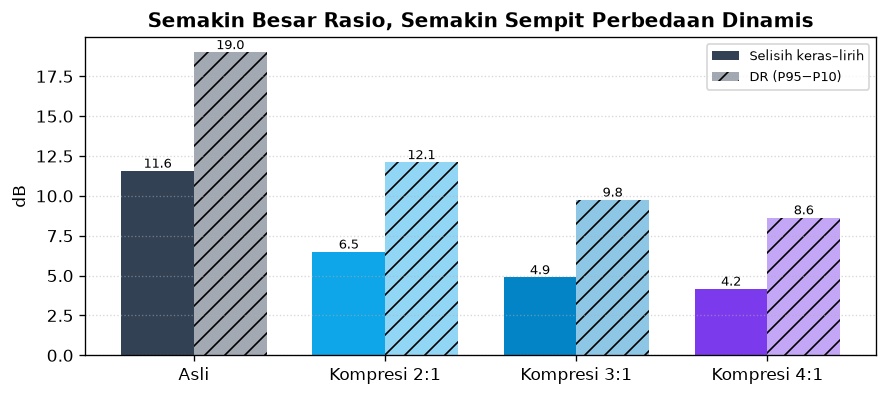

In [11]:
hasil = {}
for k, x in versi.items():
    _, e = amplop_db(x, sr)
    _, e_mentah = amplop_db(mentah[k], sr)
    hasil[k] = {
        'selisih': np.median(e[keras]) - np.median(e[lirih]),
        'dr': rentang_dinamika(x),
        'gr_lirih': np.median(e_mentah[lirih] - env_db[lirih]),
        'gr_keras': np.median(e_mentah[keras] - env_db[keras]),
        'crest': peak_db(x) - rms_db(x),
        'peak': peak_db(x),
    }

print(f"Threshold {THRESHOLD_DB:.0f} dBFS | attack {ATTACK_MS:.0f} ms | release {RELEASE_MS:.0f} ms | semua versi @ {TARGET_LUFS:.0f} LUFS\n")
print(f"{'Versi':<6}{'Selisih keras-lirih':>21}{'DR':>9}{'GR lirih':>11}{'GR keras':>11}{'Crest':>9}{'Peak':>10}")
print("-" * 77)
for k, h in hasil.items():
    print(f"{k:<6}{h['selisih']:>18.1f} dB{h['dr']:>6.1f} dB{h['gr_lirih']:>8.1f} dB{h['gr_keras']:>8.1f} dB"
          f"{h['crest']:>6.1f} dB{h['peak']:>6.1f} dBFS")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
nama = list(hasil)
pos = np.arange(len(nama))
lebar = 0.38
b1 = ax.bar(pos - lebar / 2, [hasil[k]['selisih'] for k in nama], lebar,
            color=[WARNA[k] for k in nama], label='Selisih keras–lirih')
b2 = ax.bar(pos + lebar / 2, [hasil[k]['dr'] for k in nama], lebar,
            color=[WARNA[k] for k in nama], alpha=0.45, hatch='//', label='DR (P95−P10)')
ax.bar_label(b1, fmt='%.1f', fontsize=8)
ax.bar_label(b2, fmt='%.1f', fontsize=8)
ax.set_xticks(pos, ['Asli' if k == 'Asli' else f'Kompresi {k}' for k in nama])
ax.set_ylabel("dB")
ax.set_title("Semakin Besar Rasio, Semakin Sempit Perbedaan Dinamis", fontweight='bold')
ax.legend(fontsize=8)
ax.grid(True, axis='y', ls=':', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Playback A/B

Semua pemutar memakai `normalize=False` dan sudah disamakan di −16 LUFS, jadi volume rata-rata setara. Dengarkan terutama **transisi lirih → keras**:
- **Asli**: lonjakan volume terasa mengagetkan.
- **2:1**: lonjakan melunak, dinamika masih terasa alami.
- **3:1**: bagian keras dan lirih sudah cukup rata — umum dipakai untuk vokal/podcast.
- **4:1**: paling rata dan "padat", tetapi mulai kehilangan ekspresi; *pumping* dan derau latar di bagian lirih mulai lebih terdengar.

In [12]:
for k, x in versi.items():
    judul = "🔊 Audio asli" if k == 'Asli' else f"🎛️ Kompresi {k}"
    putar(x, sr, f"{judul} (@ {TARGET_LUFS:.0f} LUFS):")

# Pembanding: kompresi 4:1 TANPA makeup gain — terdengar jauh lebih pelan daripada aslinya
putar(mentah['4:1'], sr, "\n🔉 Kompresi 4:1 sebelum makeup gain (level apa adanya):")

🔊 Audio asli (@ -16 LUFS):


🎛️ Kompresi 2:1 (@ -16 LUFS):


🎛️ Kompresi 3:1 (@ -16 LUFS):


🎛️ Kompresi 4:1 (@ -16 LUFS):



🔉 Kompresi 4:1 sebelum makeup gain (level apa adanya):


## 8. Kesimpulan

**Dinamika audio asli.** Rekaman ini bergantian antara bagian lirih (±−19 dBFS RMS) dan bagian keras (±−8 dBFS RMS), dengan selisih ±11.6 dB dan rentang dinamika (P95−P10) ±19 dB. Bagian kerasnya juga sudah **ter-*clip* sejak direkam** (±2.8% sampel menyentuh 0 dBFS, tampak sebagai puncak datar di waveform). Kompresor **tidak bisa memulihkan** puncak yang sudah terpotong; *clipping* hanya bisa dicegah saat perekaman dengan menurunkan *input gain*.

**Threshold −15 dBFS** dipilih dari median level frame aktif, tepat di celah antara kelompok lirih dan keras. Hasilnya sesuai harapan: *gain reduction* di bagian lirih hanya ±1 dB (sisa *release* dari bagian keras sebelumnya), sedangkan bagian keras ditekan ±6–9 dB.

**Perbandingan rasio (semua @ −16 LUFS):**

| Rasio | Selisih keras–lirih | DR | Karakter |
|---|---|---|---|
| Asli | 11.6 dB | 19.0 dB | lonjakan volume mengagetkan |
| 2:1 | 6.5 dB | 12.1 dB | halus, dinamika masih alami |
| 3:1 | 4.9 dB | 9.8 dB | seimbang, rata tetapi masih ekspresif |
| 4:1 | 4.2 dB | 8.6 dB | paling padat, mulai terdengar "dipencet" |

1. **Hasilnya makin kecil setiap rasio dinaikkan (*diminishing returns*).** Lompatan 1:1 → 2:1 memangkas ±5 dB perbedaan keras–lirih, tetapi 3:1 → 4:1 hanya menambah ±0.7 dB. Ini wajar karena bagian keras hanya ±7 dB di atas threshold; rasio yang lebih besar hanya mengubah sisa yang sedikit itu.
2. **Derau latar ikut naik.** Setelah penyamaan loudness, *noise floor* naik dari ±−40 dBFS (asli) menjadi ±−30 dBFS (4:1), terlihat jelas di plot amplop RMS. Makin kuat kompresi, makin besar *makeup gain*, dan desis di jeda ikut terangkat. Karena itu pada rantai mastering, **Noise Gate dipasang sebelum Compressor** (Modul 05).
3. **Peak naik mendekati 0 dBFS** (−5.9 → −0.4 dBFS) karena attack 5 ms meloloskan transien awal. Jika loudness dinaikkan lagi, perlu **Limiter** di akhir rantai.
4. **Rekomendasi untuk audio ini: rasio 3:1 dengan threshold −15 dBFS.** Perbedaan keras–lirih sudah turun lebih dari separuh (11.6 → 4.9 dB) tanpa kehilangan ekspresi seperti 4:1, dan *noise floor* masih lebih rendah daripada versi 4:1.